In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
train_df = pd.read_csv("../data/processed/train_data.csv")
test_df = pd.read_csv("../data/processed/test_data.csv")

train_df["date"] = pd.to_datetime(train_df["date"])
test_df["date"] = pd.to_datetime(test_df["date"])

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

train_df.head()

Training data shape: (1464, 7)
Testing data shape: (367, 7)


,date,daily_consumption,avg_temperature,daily_rain,daily_sun_total,avg_sun,hourly_records
0,2016-01-01,41759,3.158333,1.0,7,0.291667,24
1,2016-01-02,52185,11.000000,7.0,3,0.125000,24
2,2016-01-03,49846,0.425000,0.0,34,1.416667,24
3,2016-01-04,50510,7.633333,0.0,62,2.583333,24
4,2016-01-05,45595,9.537500,1.0,73,3.041667,24


In [4]:
# Extract daily water consumption
train_values = train_df["daily_consumption"].values.reshape(-1, 1)
test_values = test_df["daily_consumption"].values.reshape(-1, 1)

# Create scaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Fit only on training data
train_scaled = scaler.fit_transform(train_values)

# Transform testing data using the same scaler
test_scaled = scaler.transform(test_values)

print("Training data shape:", train_scaled.shape)
print("Testing data shape:", test_scaled.shape)

print("First 5 scaled training values:")
print(train_scaled[:5])

Training data shape: (1464, 1)
Testing data shape: (367, 1)
First 5 scaled training values:
[[0.00968634]
 [0.24786969]
 [0.19443493]
 [0.20960409]
 [0.09732027]]


In [5]:
# Number of previous days used for prediction
lookback = 28

X_train, y_train = [], []

for i in range(lookback, len(train_scaled)):
    X_train.append(train_scaled[i-lookback:i, 0])
    y_train.append(train_scaled[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)

# Reshape for LSTM
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1436, 28, 1)
y_train shape: (1436,)


In [6]:
from tensorflow.keras.layers import Input

lstm_model = Sequential([
    Input(shape=(28, 1)),

    LSTM(50, return_sequences=True),
    Dropout(0.2),

    LSTM(25),
    Dropout(0.2),

    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 28, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 25)             │         7,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,026 (70.41 KB)

 Trainable params: 18,026 (70.41 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")

Epoch 1/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - loss: 0.0179 - val_loss: 0.0082
Epoch 2/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0141 - val_loss: 0.0085
Epoch 3/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0150 - val_loss: 0.0074
Epoch 4/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0143 - val_loss: 0.0078
Epoch 5/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0142 - val_loss: 0.0081
Epoch 6/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0134 - val_loss: 0.0078
Epoch 7/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0141 - val_loss: 0.0076
Epoch 8/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0138 - val_loss: 0.0082
Epoch 9/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0141 - val_loss: 0.0086
Epoch 10/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0143 - val_loss: 0.0084
Epoch 11/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0133 - val_loss: 0.0095
LSTM training completed!


In [8]:
lstm_predictions = []

for start in range(0, len(test_scaled), 7):

    end = min(start + 7, len(test_scaled))

    # Use training data and actual test history
    history_values = np.concatenate([
        train_scaled.flatten(),
        test_scaled[:start].flatten()
    ])

    # Predict each day in this 7-day block
    for i in range(start, end):

        # Take previous 28 days
        input_sequence = history_values[-lookback:]

        # Reshape for LSTM
        input_sequence = input_sequence.reshape(1, lookback, 1)

        # Predict next day
        prediction = lstm_model.predict(
            input_sequence,
            verbose=0
        )[0, 0]

        lstm_predictions.append(prediction)

        # Add prediction to history
        history_values = np.append(
            history_values,
            prediction
        )

# Convert predictions to array
lstm_predictions = np.array(lstm_predictions)

# Convert scaled predictions back to original units
lstm_predictions = scaler.inverse_transform(
    lstm_predictions.reshape(-1, 1)
).flatten()

print("Total predictions:", len(lstm_predictions))
print("First 5 predictions:", lstm_predictions[:5])

Total predictions: 367
First 5 predictions: [52960.035 52975.574 53046.45  53152.824 53278.316]


In [9]:
actual = test_df["daily_consumption"].values

lstm_mae = mean_absolute_error(
    actual, lstm_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(actual, lstm_predictions)
)

lstm_mape = np.mean(
    np.abs((actual - lstm_predictions) / actual)
) * 100

print("LSTM Model Performance")
print("----------------------")
print("MAE:", lstm_mae)
print("RMSE:", lstm_rmse)
print("MAPE:", lstm_mape, "%")

LSTM Model Performance
----------------------
MAE: 5753.52294921875
RMSE: 8585.894478736622
MAPE: 8.679965294876226 %


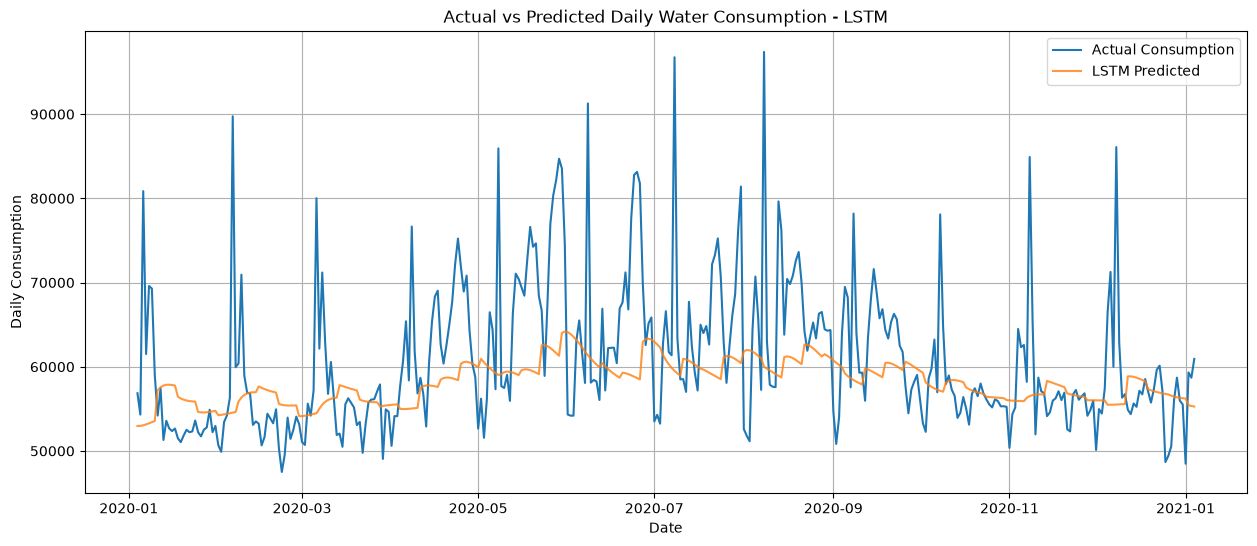

In [10]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_df["date"],
    actual,
    label="Actual Consumption"
)

plt.plot(
    test_df["date"],
    lstm_predictions,
    label="LSTM Predicted",
    alpha=0.8
)

plt.title("Actual vs Predicted Daily Water Consumption - LSTM")
plt.xlabel("Date")
plt.ylabel("Daily Consumption")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import os
import joblib

os.makedirs("../results/forecasts", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../ml/saved_models", exist_ok=True)

# Save predictions
lstm_results = pd.DataFrame({
    "date": test_df["date"],
    "actual": actual,
    "lstm_predicted": lstm_predictions
})

lstm_results.to_csv(
    "../results/forecasts/lstm_predictions.csv",
    index=False
)

# Save metrics
lstm_metrics = pd.DataFrame({
    "Model": ["LSTM"],
    "MAE": [lstm_mae],
    "RMSE": [lstm_rmse],
    "MAPE (%)": [lstm_mape]
})

lstm_metrics.to_csv(
    "../results/metrics/lstm_metrics.csv",
    index=False
)

# Save trained model
lstm_model.save("../ml/saved_models/lstm_model.keras")

# Save scaler
joblib.dump(
    scaler,
    "../ml/saved_models/lstm_scaler.pkl"
)

print("LSTM model and results saved successfully!")

LSTM model and results saved successfully!


: 